# Домашнее задание 1: Сверточные нейронные сети

In [2]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import metrics
import seaborn as sns

# инициализировать начальные значения (seeds) различных генераторов 
# случайных чисел так, чтобы при каждом запуске notebook получались одни и те же результаты
keras.utils.set_random_seed(42)

I0000 00:00:1795578399.818185  711721 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795578399.864732  711721 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795578401.102017  711721 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


# Введение

Ваша задача в этом упражнении — определить эмоцию по изображению лица. Для этого мы воспользуемся набором данных Facial Expression Recognition (FER) 2013 года.

Датасет содержит около 36 000 изображений, каждое из которых размечено одной из семи категорий:
* гнев (angry)
* отвращение (disgust)
* страх (fear)
* радость (happy)
* грусть (sad)
* удивление (surprise)
* нейтральное состояние (neutral)

Цель данного домашнего задания — показать вам, как:

1. Создать сверточную нейронную сеть (CNN) *с нуля* для распознавания эмоций на изображениях лиц (задачи 1 и 2).
2. Применить аугментацию данных для увеличения объема обучающей выборки (задача 3).
3. Использовать метод переноса обучения (transfer learning) для адаптации предобученной модели к решению той же задачи (задача 4).

Но для начала давайте загрузим данные.

In [3]:
#!wget -q -O fer2013.csv -P ./ https://dl.dropbox.com/scl/fi/e2ik6aryemboameq1rwwn/fer2013.csv?rlkey=ux7tyge6flk9nnuul9desizgf&dl=0

Данные содержат 35 887 строк и 3 столбца:
* Emotion — эмоция, закодированная числами от 0 (гнев) до 6 (нейтральное состояние).
* Pixels — список чисел, разделенных пробелами, которые представляют пиксели изображения.
* Usage — на этот столбец можно не обращать внимания.

In [4]:
data = pd.read_csv("fer2013.csv")
data

,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training
3,4,24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...,Training
4,6,4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...,Training
...,...,...,...
35882,6,50 36 17 22 23 29 33 39 34 37 37 37 39 43 48 5...,PrivateTest
35883,3,178 174 172 173 181 188 191 194 196 199 200 20...,PrivateTest
35884,0,17 17 16 23 28 22 19 17 25 26 20 24 31 19 27 9...,PrivateTest
35885,3,30 28 28 29 31 30 42 68 79 81 77 67 67 71 63 6...,PrivateTest


Значения пикселей для каждого изображения представлены в виде списка чисел, разделенных пробелами. Сколько пикселей в одном изображении?

In [5]:
len(data.loc[0, 'pixels'].split(' '))

2304

### Предварительная обработка пикселей (независимая переменная)

Каждое изображение представлено в виде списка из 2304 пикселей. Далее мы преобразуем его в изображение размером 48x48.

Напомним, что цветное изображение представляется в виде тензора размерности N × M × 3, где число 3 соответствует трем цветовым каналам (красному, зеленому и синему). Изображения из набора данных FER 2013 являются полутоновыми (черно-белыми) и содержат только один канал, отражающий интенсивность черного цвета. С такими данными работать неудобно, поскольку многие предобученные модели (в том числе та, которую мы будем использовать в задаче 4) требуют, чтобы входное изображение имело 3 канала.

Чтобы решить эту проблему, мы преобразуем каждый тензор размером 48 × 48 в тензор размерности 48 × 48 × 3, просто продублировав исходное изображение трижды. Можно считать, что в полутоновом изображении красный, зеленый и синий цветовые каналы полностью идентичны.

Приведенный ниже код преобразует наш набор данных в тензор размерности (35887, 48, 48, 3) — то есть в массив из 35887 изображений, каждое из которых представляет собой тензор размерности (48, 48, 3).

In [6]:
pixels = data['pixels'].tolist()
width, height = 48, 48
faces = []
for pixel_sequence in pixels:
    face = [int(pixel) for pixel in pixel_sequence.split(' ')] # считывать каждое лицо как одномерный массив
    face = np.asarray(face).reshape(width, height) # преобразовать одномерный массив длиной 2304 в массив размером 48x48
    face = np.stack((face,)*3, axis=-1)
    faces.append(face.astype('float32'))

faces = np.asarray(faces)
faces.shape

(35887, 48, 48, 3)

Для первого изображения, то есть `faces[0]`, можно рассмотреть его первый канал (соответствующий "красному").

In [7]:
faces[0,:,:,0]

array([[ 70.,  80.,  82., ...,  52.,  43.,  41.],
       [ 65.,  61.,  58., ...,  56.,  52.,  44.],
       [ 50.,  43.,  54., ...,  49.,  56.,  47.],
       ...,
       [ 91.,  65.,  42., ...,  72.,  56.,  43.],
       [ 77.,  82.,  79., ..., 105.,  70.,  46.],
       [ 77.,  72.,  84., ..., 106., 109.,  82.]],
      shape=(48, 48), dtype=float32)

Это в точности то же самое, что и для второго канала (соответствующего «синему»). Аналогичным образом — для зелёного.

### Предварительная обработка данных об эмоциях (зависимая переменная)

Далее рассмотрим, как кодируются эмоции (зависимая переменная). Принято следующее обозначение: 0 — 'гнев', 1 — 'отвращение', ..., 6 — 'нейтральное состояние'.

In [8]:
data.emotion.unique()

array([0, 2, 4, 6, 3, 5, 1])

Мы преобразуем эмоцию в one-hot-кодирование с помощью функции pd.get_dummies.

In [9]:
emotions = pd.get_dummies(data['emotion']).to_numpy() # каждая эмоция кодируется в виде 7-мерного вектора по принципу 'one-hot'
emotions_names = ('angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral')
emotions.shape

(35887, 7)

### Примеры изображений
Давайте взглянем на некоторые из этих забавных изображений!

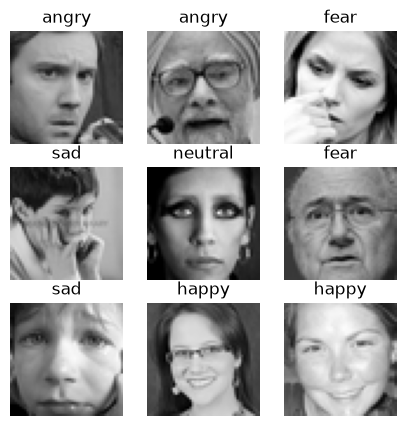

In [10]:
fig = plt.figure(figsize=(5, 5)) #(10, 10) was
for i in range(9):
    ax = fig.add_subplot(3, 3, i+1)
    ax.set_title(f"{emotions_names[np.argmax(emotions[i])]}")
    ax.imshow(faces[i].astype('uint8'))
    ax.axis('off')

### Разделение на обучающую и тестовую выборки
Как и в исходном наборе данных, мы выделим первые 28 709 изображений для обучения, а остальные — для тестирования.

In [11]:
train_faces, train_emotions =  faces[:28709], emotions[:28709]
test_faces, test_emotions =  faces[28709:], emotions[28709:]

train_faces.shape, train_emotions.shape, test_faces.shape, test_emotions.shape

((28709, 48, 48, 3), (28709, 7), (7178, 48, 48, 3), (7178, 7))

# Задача 1: Базовая модель [30 баллов]
В этой задаче мы создадим простую свёрточную нейронную сеть (CNN), состоящую из трёх свёрточных блоков, одного полносвязного слоя и одного выходного слоя.

## Часть (a): Построение модели [10 баллов]
Нам необходимо создать сверточную нейронную сеть (CNN), структура которой приведена в описании модели. Заполните код в ячейке ниже так, чтобы результат выполнения `model.summary()` соответствовал приведенному выше изображению. Обязательно используйте функцию активации `relu` для всех слоев `Conv2D`, а для выходного слоя — соответствующую функцию активации.


![](cnn_model.png)

In [12]:
input = keras.Input(shape=(48, 48, 3), name="input")

###### ВАШ КОД ЗДЕСЬ #####
h = input / 255.0

h = keras.layers.Conv2D(16, (2, 2), activation="relu")(h)
h = keras.layers.MaxPooling2D()(h)

h = keras.layers.Conv2D(16, (2, 2), activation="relu")(h)
h = keras.layers.MaxPooling2D()(h)

h = keras.layers.Conv2D(16, (2, 2), activation="relu")(h)
h = keras.layers.MaxPooling2D()(h)

h = keras.layers.Flatten()(h)

h = keras.layers.Dense(256)(h)

output = keras.layers.Dense(7, activation="softmax", name="output")(h)

###### ВАШ КОД ЗДЕСЬ #####

model = keras.Model(input, output, name='CNN_model')
model.summary()

E0000 00:00:1795578423.341631  711721 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "CNN_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 47, 47, 16)     │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 22, 22, 16)     │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 11, 11, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 10, 16)     │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       102,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,743 (416.96 KB)

 Trainable params: 106,743 (416.96 KB)

 Non-trainable params: 0 (0.00 B)

## Часть (b): Количество параметров [10 баллов]
Приведенная выше модель содержит $106\,743$ обучаемых параметра; это число складывается следующим образом: $208 + 1040 + 1040 + 102\,656 + 1799$. Объясните, как получено каждое из этих пяти чисел, и приведите соответствующие расчеты (например, $208 = 16 \times 3 \times 4 + 16$).

<font color='red'>**ВАШ ОТВЕТ.**</font>

_Слои Max_Pooling, rescaling и flatten - мат. преобразование векторов -> не имеют обучаемых параметров_

_Conv2D - Свёрточные слои с параметрами_

_Размер ядра умножаем на количество канлов цвета в изображении (как бы берём участок изображения 2x2 со всеми цветовыми каналами)_

$12 = 2 \times 2 \times 3$

_Первый - Ядро умножаем на количество фильтров(16) + смещение(16)_

$208 = 12 \times 16 + 16$

_Два последующих_

$1040 = 2 \times 2 \times 16 \times 16 + 16$ 

_Dense слой_

$102656 = 400 \times 256+256$

_Выходной слой на 7 классов_

$1799=256 \times 7 + 7$

## Часть (c): Обучение и оценка [10 баллов]

Скомпилируем нашу модель и обучим её на тренировочных данных. Поскольку мы применили one-hot-кодирование к зависимой переменной, следует использовать функцию потерь `categorical_crossentropy`, а не `sparse_categorical_crossentropy`.

Заполните параметры в методах `model.compile` и `model.fit` ниже.

* Скомпилируйте модель, используя функцию потерь `categorical_crossentropy` и оптимизатор `adam`; в качестве метрики укажите `accuracy`.
* Обучите модель на данных `train_faces` и `train_emotions`, установив размер пакета (batch size) равным 64, количество эпох — 30, а долю валидационной выборки — 20%.

In [13]:
model.compile(
    ### ВАШ КОД ЗДЕСЬ ###
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_history = model.fit(
    ### ВАШ КОД ЗДЕСЬ ###
    train_faces,
    train_emotions,
    batch_size=64,
    epochs=30,
    validation_split=0.2
)

Epoch 1/30


W0000 00:00:1795578424.142864  711721 cpu_allocator_impl.cc:82] Allocation of 634991616 exceeds 10% of free system memory.


359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3098 - loss: 1.7160

W0000 00:00:1795578433.325865  711721 cpu_allocator_impl.cc:82] Allocation of 158754816 exceeds 10% of free system memory.


359/359 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.3098 - loss: 1.7160 - val_accuracy: 0.3842 - val_loss: 1.6155
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.3907 - loss: 1.5719 - val_accuracy: 0.4164 - val_loss: 1.5439
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4211 - loss: 1.5016 - val_accuracy: 0.4467 - val_loss: 1.4804
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4486 - loss: 1.4459 - val_accuracy: 0.4631 - val_loss: 1.4324
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4650 - loss: 1.4035 - val_accuracy: 0.4730 - val_loss: 1.4006
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4768 - loss: 1.3728 - val_accuracy: 0.4815 - val_loss: 1.3791
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4867 - loss: 1.3520 - val_accuracy: 0.4836 - val_loss: 1.3665
Epoch 8/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4948 - loss: 1.3322 - val_accuracy: 0.47

**Эпохи и пакеты (батчи).**

Объясните своими словами, в чем заключается взаимосвязь между эпохой и пакетом (батчем) в контексте стохастического градиентного спуска.

<font color='red'>**Ваш ответ.**</font>

_Пожалуйста, замените этот текст своим ответом_

При запуске `model.fit` мы увидели, что на каждую эпоху приходится 359 пакетов (батчей). Объясните, пожалуйста, как было получено это число — 359. _Подсказка_: всего имеется 28 709 обучающих примеров, при этом 20% данных выделено для валидации.

<font color='red'>**Ваш ответ.**</font>

_Батч — это порция данных, после которой модель один раз обновляет веса._

_Эпоха — это один полный проход по всем данным._

_За одну эпоху модель проходит все батчи, и после каждого делает шаг СГС. Поэтому число обновлений за эпоху ~ Размер выборки / Размер Батча_

**Построение кривой точности на обучающей и валидационной выборках**

Используйте приведенную ниже функцию `plot_accuracy` для построения графика точности на обучающей и валидационной выборках в процессе обучения по эпохам.

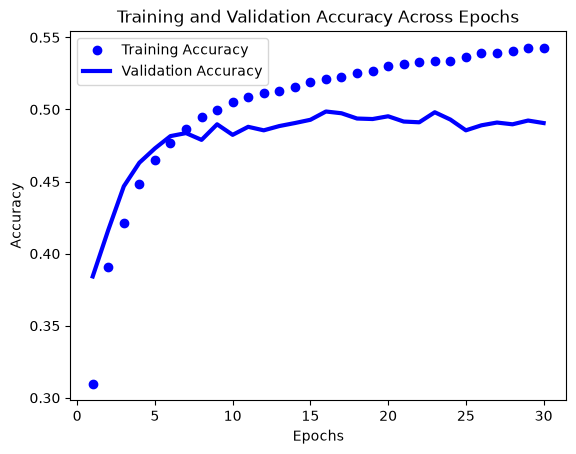

In [14]:
def plot_accuracy(model_history):
    history_dict = model_history.history
    acc = history_dict["accuracy"]
    val_acc = history_dict["val_accuracy"]
    epochs = range(1, len(acc) + 1)
    plt.plot(epochs, acc, "bo", label="Training Accuracy", linewidth=3)
    plt.plot(epochs, val_acc, "b", label="Validation Accuracy", linewidth=3)
    plt.title("Training and Validation Accuracy Across Epochs")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

plot_accuracy(model_history)

**Точность модели**

Рассчитайте точность на тестовом наборе данных. Напишите свой код ниже, чтобы продемонстрировать полученную точность.

In [20]:
 ### ВАШ КОД ЗДЕСЬ ###
test_loss, test_acc = model.evaluate(test_faces, test_emotions, verbose=0)
print(f"Точность: {test_acc:.4f}")

Точность: 0.4826


# Задача 2: Более широкие и глубокие модели [30 баллов]
В этой задаче мы модифицируем модель из задачи 1 двумя способами:
* Увеличим ширину модели, добавив больше фильтров, а также увеличив количество нейронов в полносвязном слое.
* Увеличим глубину модели, добавив еще один полносвязный слой.

### Часть (а): Более широкая модель [5 баллов]
Возьмите модель из задачи 1 и измените ее на `wider_model`, используя 32 фильтра для сверточных слоев вместо 16.

Напишите новый код ниже и убедитесь, что `wider_model.summary()` выглядит правильно. Ваша модель должна иметь 215 527 параметров.

In [16]:
input = keras.Input(shape=train_faces.shape[1:])

 ### ВАШ КОД НИЖЕ ###
h = input / 255.0

h = keras.layers.Conv2D(32, (2, 2), activation="relu")(h)
h = keras.layers.MaxPooling2D()(h)

h = keras.layers.Conv2D(32, (2, 2), activation="relu")(h)
h = keras.layers.MaxPooling2D()(h)

h = keras.layers.Conv2D(32, (2, 2), activation="relu")(h)
h = keras.layers.MaxPooling2D()(h)

h = keras.layers.Flatten()(h)

h = keras.layers.Dense(256)(h)

output = keras.layers.Dense(7, activation="softmax", name="output")(h)

### ВАШ КОД ВЫШЕ ###

wider_model = keras.Model(input, output, name='wider_cnn')
wider_model.summary()

Model: "wider_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 47, 47, 32)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 22, 22, 32)     │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 10, 10, 32)     │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       205,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 215,527 (841.90 KB)

 Trainable params: 215,527 (841.90 KB)

 Non-trainable params: 0 (0.00 B)

## Часть (b): Количество параметров [5 баллов]
Приведенная выше модель содержит $215\,527$ обучаемых параметров; это число складывается следующим образом: $416 + 4128 + 4128 + 205\,056 + 1799$. Объясните, как было получено каждое из этих пяти чисел, и приведите соответствующие расчеты.

<font color='red'>**Ваш ответ.**</font>


**Первый Conv2D(32, (2,2))**

$(2\times2\times3+1)\times32 = 416$


**Второй и Третий Conv2D(32, (2,2))**

$(2\times2\times32+1)\times32 = 4128$


**Dense(256)**: после свёрток и пулингов размер карты становится $5\times5\times32=800$, поэтому

$800\times256 + 256 = 205056$


**Выходной Dense(7)**:

$256\times7 + 7 = 1799$


Итого:

$416 + 4128 + 4128 + 205056 + 1799 = 215527$


MaxPooling, деление на 255 и Flatten обучаемых параметров не имеют.

## Часть (c): Обучение и оценка [5 баллов]
Давайте обучим нашу модель и оценим её эффективность.

In [21]:
wider_model.compile(
    ### ВАШ КОД ЗДЕСЬ ###
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

wider_model_history = wider_model.fit(
    ### ВАШ КОД ЗДЕСЬ ###
    train_faces,
    train_emotions,
    batch_size=64,
    epochs=30,
    validation_split=0.2
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.3245 - loss: 1.6908 - val_accuracy: 0.3959 - val_loss: 1.5528
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.4284 - loss: 1.4941 - val_accuracy: 0.4498 - val_loss: 1.4451
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.4688 - loss: 1.3914 - val_accuracy: 0.4742 - val_loss: 1.3904
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.4912 - loss: 1.3321 - val_accuracy: 0.4930 - val_loss: 1.3481
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.5125 - loss: 1.2878 - val_accuracy: 0.4995 - val_loss: 1.3464
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.5226 - loss: 1.2538 - val_accuracy: 0.5023 - val_loss: 1.3266
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.5344 - loss: 1.2256 - val_accuracy: 0.5044 - val_loss: 1.3257
Epoch 8/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.5447 - loss: 1.2047 - 

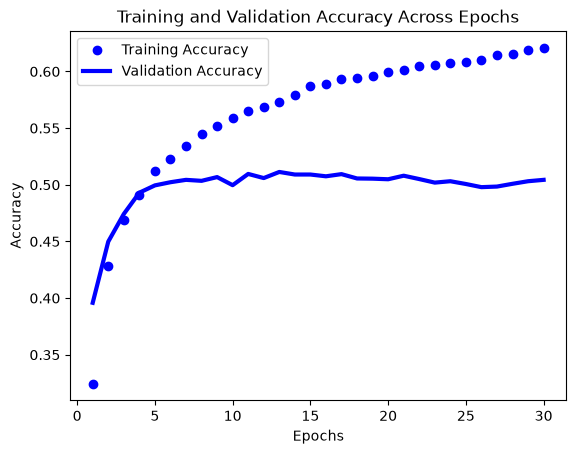

In [22]:
plot_accuracy(wider_model_history)

In [24]:
# Рассчитайте точность на тестовых данных
test_loss2, test_acc2 = wider_model.evaluate(test_faces, test_emotions, verbose=0)
print(f"Точность: {test_acc2:.4f}")
### ВАШ КОД ЗДЕСЬ ###

Точность: 0.4869


Сравните кривую точности для `wider_model` с аналогичной кривой для `model` из задачи 1. В каком случае после 30 эпох наблюдается больше признаков переобучения? Логично ли это?

<font color='red'> **Ваш ответ.** </font>

На графике для wider_model разрыв между кривыми точности больше, а validation accuracy выходит на плато раньше, чем у базовой model. Это означает, что более широкая модель (32 фильтра вместо 16) быстрее запоминает обучающую выборку и раньше перестаёт улучшать обобщение. Вывод: wider_model переобучается сильнее, что логично из-за большего числа параметров (215527) и, соответственно, большей ёмкости модели.



## Часть (d): Более глубокая модель [5 баллов]
Теперь создайте новую модель под названием `deep_model`, взяв за основу `model` из задачи 1 и добавив еще один полносвязный (dense) слой из 256 нейронов сразу после исходного полносвязного слоя (также состоящего из 256 нейронов). В новой модели должно быть в общей сложности 2 полносвязных слоя по 256 нейронов в каждом, а общее количество параметров должно составлять 172 535.

Обучите модель, постройте график зависимости точности от количества эпох с помощью функции `plot_accuracy` и укажите точность модели на тестовом наборе данных.

In [25]:
input = keras.Input(shape=train_faces.shape[1:])

### ВАШ КОД НИЖЕ ###
h = input / 255.0

h = keras.layers.Conv2D(16, (2, 2), activation="relu")(h)
h = keras.layers.MaxPooling2D()(h)

h = keras.layers.Conv2D(16, (2, 2), activation="relu")(h)
h = keras.layers.MaxPooling2D()(h)

h = keras.layers.Conv2D(16, (2, 2), activation="relu")(h)
h = keras.layers.MaxPooling2D()(h)

h = keras.layers.Flatten()(h)

h = keras.layers.Dense(256)(h)
h = keras.layers.Dense(256)(h)

output = keras.layers.Dense(7, activation="softmax", name="output")(h)

### ВАШ КОД ВЫШЕ ###

deeper_model = keras.Model(input, output, name='deeper_cnn')
deeper_model.summary()

Model: "deeper_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_2 (TrueDivide)      │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 47, 47, 16)     │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 23, 23, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 22, 22, 16)     │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 11, 11, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 10, 10, 16)     │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       102,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 172,535 (673.96 KB)

 Trainable params: 172,535 (673.96 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
deeper_model.compile(
    ### ВАШ КОД ЗДЕСЬ ###
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

deeper_model_history = deeper_model.fit(
    ### ВАШ КОД ЗДЕСЬ ###
    train_faces,
    train_emotions,
    batch_size=64,
    epochs=30,
    validation_split=0.2
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.3240 - loss: 1.6927 - val_accuracy: 0.3906 - val_loss: 1.5870
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.3969 - loss: 1.5507 - val_accuracy: 0.4225 - val_loss: 1.5116
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4305 - loss: 1.4792 - val_accuracy: 0.4451 - val_loss: 1.4588
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4503 - loss: 1.4312 - val_accuracy: 0.4556 - val_loss: 1.4213
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4644 - loss: 1.3964 - val_accuracy: 0.4606 - val_loss: 1.4125
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4742 - loss: 1.3743 - val_accuracy: 0.4646 - val_loss: 1.4005
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4817 - loss: 1.3578 - val_accuracy: 0.4610 - val_loss: 1.4012
Epoch 8/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4897 - loss: 1.3401 - val_accu

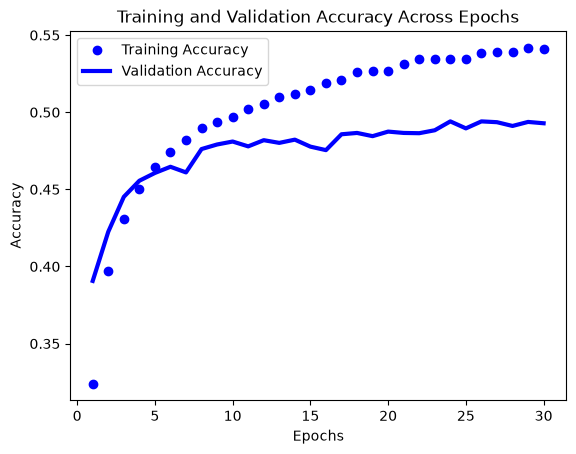

In [27]:
plot_accuracy(deeper_model_history)

In [28]:
# Рассчитайте точность на тестовых данных
### ВАШ КОД ЗДЕСЬ ###
deeper_model.evaluate(test_faces, test_emotions)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4785 - loss: 1.3814


[1.3813732862472534, 0.47854554653167725]

## Часть (e): Сравнение [10 баллов]
Прокомментируйте различия в точности на тестовой выборке для моделей `model`, `wider_model` и `deeper_model`. Что привело к лучшим результатам — увеличение ширины модели или её глубины? Почему? Как вы считаете, будет ли этот вывод справедлив для любых других задач?

<font color='red'>**Ваш ответ**</font>

Сравнение точности на тестовой выборке:
* `model`: 48,26%
* `wider_model`: 48,69%
* `deeper_model`: 47,85%

_Пожалуйста, впишите значения выше и замените этот текст своим ответом._

# Проблема 3: Увеличение данных [15 баллов]

Основная идея дополнения состоит в том, чтобы изменить изображение настолько незначительно, чтобы значение зависимой переменной (т. е. категории, к которой оно принадлежит) не изменилось.

Keras позволяет нам легко выполнять увеличение данных, используя такие слои, как:

* `keras.layers.RandomFlip`
* `keras.layers.RandomZoom`
* `keras.layers.RandomRotation`

Давайте быстро посмотрим, что именно делает аугментация... В данном случае мы отражаем изображения по горизонтали, а затем применяем к ним случайное масштабирование (зум) — до 20%. Заметьте: вам не обязательно вникать в то, как работает приведенный ниже код. Большая его часть нужна лишь для того, чтобы мы могли наглядно увидеть процесс аугментации.

In [ ]:
def augment_images(image):
    x = keras.layers.RandomFlip("horizontal")(image)
    x = keras.layers.RandomZoom(0.2)(x)
    return x

augmented_images = [augment_images(np.expand_dims(train_faces[0],axis=0)) for i in range(9)]
fig = plt.figure(figsize=(10, 10))
for i in range(9):
    ax = fig.add_subplot(3, 3, i+1, xticks=[], yticks=[])
    ax.imshow(tf.keras.preprocessing.image.array_to_img(augmented_images[i][0]), cmap='gray', vmin=0, vmax=255)

Мы берем нашу модель `wider_model` из задачи 2(c) и добавляем в нее случайное отражение (random flip) и случайное масштабирование (random zoom) в качестве **слоев**, расположенных перед слоем изменения масштаба (rescaling layer).

In [ ]:
input = keras.Input(shape=(48, 48, 3))

### АУГМЕНТАЦИЯ ДАННЫХ ###
x = keras.layers.RandomFlip("horizontal")(input)
x = keras.layers.RandomZoom(0.2)(x)

### ВАШ КОД ЗДЕСЬ ###
# Пожалуйста, вставьте сюда свой код из wider_model.

model_augmented = keras.Model(input, output, name='augmented_CNN_model')
model_augmented.summary()

Обучите модель (используя те же параметры, что и во всех предыдущих вопросах), постройте график зависимости точности от эпохи и укажите точность на тестовой выборке.

In [ ]:
model_augmented.compile(
   ### ВАШ КОД ЗДЕСЬ ###
)

model_augmented_history = model_augmented.fit(
   ### ВАШ КОД ЗДЕСЬ ###
)

In [ ]:
plot_accuracy(model_augmented_history)

In [ ]:
# Рассчитайте точность на тестовых данных
### ВАШ КОД ЗДЕСЬ ###
deeper_model.evaluate(test_faces, test_emotions)

Сравните это с `wider_model` и прокомментируйте влияние аугментации данных.

* Помогла ли аугментация данных уменьшить переобучение?
* Улучшила ли аугментация данных точность на тестовой выборке?

<font color='red'> **Ваш ответ.** </font>

_Пожалуйста, замените этот текст своим ответом_

# Задача 4: Перенос обучения (Transfer Learning) и дообучение (Fine-Tuning) [25 баллов]

Далее мы применим метод переноса обучения к нашей задаче, используя VGG19 — предобученную модель, аналогичную рассмотренной на занятиях ResNet50. Мы возьмем VGG19, удалим из нее «голову» (последние полносвязные слои) и подключим к ней нашу собственную «небольшую» нейронную сеть.

Мы рассмотрим три различных подхода:

1. Часть (a): **Базовый перенос обучения (Base Transfer Learning)**. Веса «усеченной» модели VGG19 фиксируются (остаются неизменными), а обучаются только веса нашей небольшой нейронной сети.
2. Часть (b): **Частичное дообучение (Fine-Tuning)**. Веса верхних 6 слоев (из 19) модели VGG19 фиксируются, а веса остальных 13 слоев — наряду с весами нашей небольшой нейронной сети — оптимизируются с помощью алгоритмов SGD или Adam.
3. Часть (c): **Полное дообучение (Fine-Tuning)**. Все веса модели VGG19, а также веса нашей небольшой нейронной сети, подлежат обучению (настройке).

Для каждой из моделей мы построим графики точности (accuracy) на обучающей и валидационной выборках, вычислим точность на тестовой выборке, а также построим матрицу ошибок (confusion matrix).

## Часть (a): Без дообучения (Fine-tuning) [5 баллов]

Загрузим модель VGG19, указав параметр `include_top=False`, чтобы исключить её выходной слой. Также установим `trainable=False`, тем самым обозначив, что параметры этих 19 слоёв не подлежат обучению.

In [ ]:
base_model = keras.applications.VGG19(
    include_top=False,   # это делает VGG19 «безголовой»
    weights="imagenet",
    input_tensor=None,
    input_shape=(48, 48, 3),
    pooling=None,
    classes=1000,
    classifier_activation="softmax",
)

# Заморозьте base_model, чтобы она стала полностью не подлежащей обучению
base_model.trainable = False

Мы создаем нейронную сеть, которая выполняет аугментацию и масштабирование данных, затем использует архитектуру VGG19, а перед выходным слоем содержит один полносвязный слой.

In [ ]:
inputs = keras.Input(shape=(48,48,3))

x = keras.layers.RandomFlip("horizontal")(inputs)
x = keras.layers.RandomZoom(0.2)(x)
x = keras.layers.Rescaling(1./255)(x) # нормализация

# Добавляйте слои из base_model по одному
for layer in base_model.layers:
    x = layer(x)

x = keras.layers.Flatten()(x)
x = keras.layers.Dense(256, activation='relu')(x)
outputs = keras.layers.Dense(7, activation='softmax')(x)

transfer_model = keras.Model(inputs, outputs, name='transfer_model')
transfer_model.summary()

Обучите модель. Здесь мы используем скорость обучения (learning rate), равную 0.00002, для достижения лучшей сходимости.

In [ ]:
transfer_model.compile(loss='categorical_crossentropy',
            optimizer=keras.optimizers.Adam(2e-5),
            metrics=['accuracy'])

transfer_model_history = transfer_model.fit(train_faces, train_emotions, epochs=30, validation_split=0.2)

Мы можем построить кривую точности на обучающей и валидационной выборках.

In [ ]:
plot_accuracy(transfer_model_history)

Давайте также вычислим матрицу ошибок (confusion matrix) и точность (accuracy) на тестовом наборе данных.

Ниже для вас подготовлена ​​функция `show_confusion_matrix`. Её можно применить к любой модели Keras; она выполнит следующие расчёты:
* Точность на тестовых данных.
* Матрицу ошибок. Напомним, что каждая строка матрицы соответствует истинным меткам классов, а каждый столбец — предсказанным. Например, если значение в строке «happy» и столбце «sad» равно 250, это означает, что в тестовом наборе есть 250 примеров, для которых истинная метка — «happy», а модель предсказала «sad».
* Тепловую карту (heatmap) матрицы ошибок, в которой каждая строка нормализована так, что сумма её элементов равна 1,0. Например, если значение в строке «happy» и столбце «sad» равно 0,25, это значит, что 25% примеров с истинной меткой «happy» были классифицированы как «sad».

In [ ]:
from IPython.display import display

def show_confusion_matrix(model):
    """
    Calculates the test accuracy, confusion matrix and heat map for a model.
    """
    global test_faces, test_emotions, emotions_names

    y_pred = model.predict(test_faces).argmax(axis=1)
    y_actual = test_emotions.argmax(axis=1)

    print('*************************\n* Test Accuracy: %.4f *\n*************************' % metrics.accuracy_score(y_actual, y_pred))

    cm = pd.DataFrame(metrics.confusion_matrix(y_actual, y_pred), index=emotions_names, columns=emotions_names)
    display(cm)

    cm = cm.div(cm.sum(axis=1), axis=0)

    sns.heatmap(cm, cmap="Blues", annot=True, fmt=".2f")

show_confusion_matrix(transfer_model)

Пожалуйста, кратко прокомментируйте эффективность модели.

<font color='red'> **Ваш ответ** </font>

_Пожалуйста, замените этот текст своим ответом_

## Часть (b): Тонкая настройка [5 баллов]
В этой части мы позволим нашей модели оптимизации настроить **некоторые** слои сети VGG19. В частности, мы «заморозим» только первые 15 слоев, а остальные слои оставим доступными для обучения.

In [ ]:
base_model = keras.applications.VGG19(
    include_top=False,   # это делает VGG19 «безголовой»
    weights="imagenet",
    input_tensor=None,
    input_shape=None,
    pooling=None,
    classes=1000,
    classifier_activation="softmax",
)

inputs = keras.Input(shape=(48,48,3))

x = keras.layers.RandomFlip("horizontal")(inputs)
x = keras.layers.RandomZoom(0.2)(x)
x = keras.layers.Rescaling(1./255)(x) # normalizing

# Добавить слои из base_model
for layer in base_model.layers:
    x = layer(x)

x = keras.layers.Flatten()(x)
x = keras.layers.Dense(256, activation='relu')(x)
outputs = keras.layers.Dense(7, activation='softmax')(x)

partial_model = keras.Model(inputs, outputs, name='partial_fine_tune_model')

# Сделайте первые 15 слоев необучаемыми. Все остальные слои — обучаемые.
for layer in partial_model.layers[:15]:
    layer.trainable = False

partial_model.summary()

Давайте посмотрим, какие слои подлежат обучению. Заметим, что VGG19 состоит из 4 блоков сверточных фильтров (block1_conv1, block1_conv2, ..., block5_conv4). Мы разрешим обучение для блоков 4 и 5, а блоки 1, 2 и 3 «заморозим».

In [ ]:
for i, layer in enumerate(partial_model.layers):
    print('Layer %d: %s (%s), Trainable=%s' % (i+1, layer.name, layer.__class__.__name__, layer.trainable))

Обучите модель и проанализируйте кривую обучения/валидации, точность на тестовой выборке и матрицу ошибок.

In [ ]:
partial_model.compile(loss='categorical_crossentropy',
            optimizer=keras.optimizers.Adam(2e-5),
            metrics=['accuracy'])

partial_model_history = partial_model.fit(train_faces, train_emotions, epochs=30, validation_split=0.2)

In [ ]:
plot_accuracy(partial_model_history)

In [ ]:
show_confusion_matrix(partial_model)

Пожалуйста, кратко прокомментируйте эффективность модели.

<font color='red'> **Ваш ответ** </font>

_Пожалуйста, замените этот текст своим ответом_

## Часть (c): Дообучение (Fine-tuning) [5 баллов]
Теперь попробуем использовать модель, основанную на методе переноса обучения (transfer learning), в которой все слои можно дообучить.

In [ ]:
base_model = keras.applications.VGG19(
    include_top=False,   # это делает VGG19 «безголовой»
    weights="imagenet",
    input_tensor=None,
    input_shape=None,
    pooling=None,
    classes=1000,
    classifier_activation="softmax",
)

inputs = keras.Input(shape=(48,48,3))

x = keras.layers.RandomFlip("horizontal")(inputs)
x = keras.layers.RandomZoom(0.2)(x)
x = keras.layers.Rescaling(1./255)(x) # normalizing

# Добавить слои из base_model
for layer in base_model.layers:
    x = layer(x)

x = keras.layers.Flatten()(x)
x = keras.layers.Dense(256, activation='relu')(x)
outputs = keras.layers.Dense(7, activation='softmax')(x)

tuned_model = keras.Model(inputs, outputs, name='full_fine_tune_model')

# Посмотрим, какие слои являются обучаемыми
for i, layer in enumerate(tuned_model.layers):
    print('Layer %d: %s (%s), Trainable=%s' % (i+1, layer.name, layer.__class__.__name__, layer.trainable))

In [ ]:
tuned_model.compile(loss='categorical_crossentropy',
            optimizer=keras.optimizers.Adam(2e-5),
            metrics=['accuracy'])

tuned_model_history = tuned_model.fit(train_faces, train_emotions, epochs=30, validation_split=0.2)

In [ ]:
plot_accuracy(tuned_model_history)

In [ ]:
show_confusion_matrix(tuned_model)

Пожалуйста, кратко прокомментируйте эффективность модели.

<font color='red'> **Ваш ответ** </font>

_Пожалуйста, замените этот текст своим ответом_

## Часть (d): Сравнение [10 баллов]

Заполните приведенную ниже таблицу, указав точность на тестовой выборке для трех моделей, рассмотренных выше, а также для модели `wider_model` из задачи 2.

<font color='red'>**Ваш ответ.**</font>

Точность модели на тестовой выборке:
* Модель (a) без дообучения (fine-tuning): 0,00%
* Модель (b) с частичным дообучением (fine-tuning): 0,00%
* Модель (c) с дообучением (fine-tuning): 0,00%
* `wider_model` из задачи 2(a)–(c): 0,00%

Прокомментируйте эффективность моделей (a), (b) и (c). В частности, ответьте на следующие вопросы:

* Почему модели (b) и (c) показывают значительно лучшие результаты, чем `wider_model`?
* С чем, на ваш взгляд, связаны столь низкие показатели модели (a)?
* Почему, по вашему мнению, модель (c) работает лучше, чем модель (b)?

<font color='red'>**Ваш ответ.**</font>

_Пожалуйста, замените этот текст своим ответом_